In [1]:
from torchvision import transforms
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image as PILImage
import numpy as np
import os
import pandas as pd
import random
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

/data/aveera/venv/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import quantus
from quantus import PointingGame, MaxSensitivity
import glob
from PIL import Image

from pytorch_grad_cam.utils.image import preprocess_image, show_cam_on_image
from quantus import norm_func, perturb_func, similarity_func
from datetime import datetime

from xai_lib import MemoryManagement as mm
from xai_lib import AttributionEngine as att_engine
import xaibenchmark as xb
from skimage.segmentation import slic

In [3]:
name = "aveera"
PREPROCESSED_DIR = f"/data/{name}/preprocessed_idrid"
MODEL_NAMES = ["resnet50", "efficientnetb0"]
N_TEST = 81
SEED=42

In [4]:
_engine_cache = {}

def get_engine_for(model):
    """Look up the AttributionEngine that was built for this exact model object."""

    eng = _engine_cache.get(id(model))
    if eng is None:
        raise RuntimeError(
            "No AttributionEngine registered for this model."
        )
    return eng

In [5]:
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

# Lets cuDNN pick the fastest conv algorithms since our input size (224x224) is fixed
torch.backends.cudnn.benchmark = True

cuda


In [7]:
def get_predicted_labels(model, samples, device, transform=test_transform):
    """Recomputes the model's predicted class per sample."""
    preds = []
    model.eval()
    with torch.no_grad():
        for raw_img_np, _ in samples:
            input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to(device)
            pred = model(input_tensor).argmax(dim=1).item()
            preds.append(pred)
    return np.array(preds)

# **Explainable Artificial Intelligence**

**While Grad-CAM is widely applied in DR interpretability literature, disclosed hyperparameters for perturbation-based methods (LIME, SHAP) are rarely reported in DR-specific work.**

Our parameter choices were therefore informed by broader medical-imaging and XAI benchmarking literature rather than DR-specific research, while also accoutning for our resource constraints given the scale of our evaluation.

**For LIME, we set lime_samples=1000**, consistent with values used in [Gastrointestinal Endoscopic study](https://arxiv.org/pdf/2503.00780), [Sickle Cell study](https://arxiv.org/pdf/2305.01663) and [Photonic Chip study](https://arxiv.org/pdf/2505.09266) which set the number of samples to 1000 to ensure the creation of a sufficient number of perturbed samples around the input instance for accurate approximation.

**For SHAP, we set the max_evals =500**, consistent with the [Sickle Cell study](https://arxiv.org/pdf/2305.01663) from above and is also the SHAP libraries default. We also use batch_size-50 which is the SHAP library, the same justification as this study [haematopoietic stem cell study](https://pmc.ncbi.nlm.nih.gov/articles/PMC12746025/)


**We use a 32x32 blur kernel for the SHAP masker, smaller than the 128x128 kernel used in SHAP's reference examples for 224x224 natural images.** In natural-image classification, the relevant object typically occupies a large contiguous region of the frame whereas for DR lesion attribution, multiple small lesions can appear simultaneously across the image. A 128x128 kernel would blur across a majority of the image width in a single masking operation, conflating spatially distinct lesions that should be attributed independently, which is why we choose 32x32

**The XAI Attribution Engine is a single wrapper around three XAI methods, so each trained model can be explained the same way regardless of which method is used. Given a model and an image, it returns an attribution map per method highlighting the regions that most influenced the prediction**

**Loading the Refined IDRID dataset**

In [8]:
def load_preprocessed_from_disk(save_dir):
    images_out_dir = os.path.join(save_dir, "images")
    masks_out_dir = os.path.join(save_dir, "masks")

    image_paths = sorted(glob.glob(os.path.join(images_out_dir, "*.png")))
    if not image_paths:
        raise FileNotFoundError(f"No preprocessed images found in {images_out_dir}")

    samples = []
    for img_path in image_paths:
        image_id = os.path.splitext(os.path.basename(img_path))[0]
        mask_path = os.path.join(masks_out_dir, f"{image_id}.png")

        img = np.array(Image.open(img_path).convert('RGB'))
        mask = np.array(Image.open(mask_path).convert('L'))
        samples.append((img, mask))
    return samples

In [9]:
idrid_subset = load_preprocessed_from_disk(PREPROCESSED_DIR)

# **Side-by-Side Comparison of each XAI technique**

--- resnet50 ---


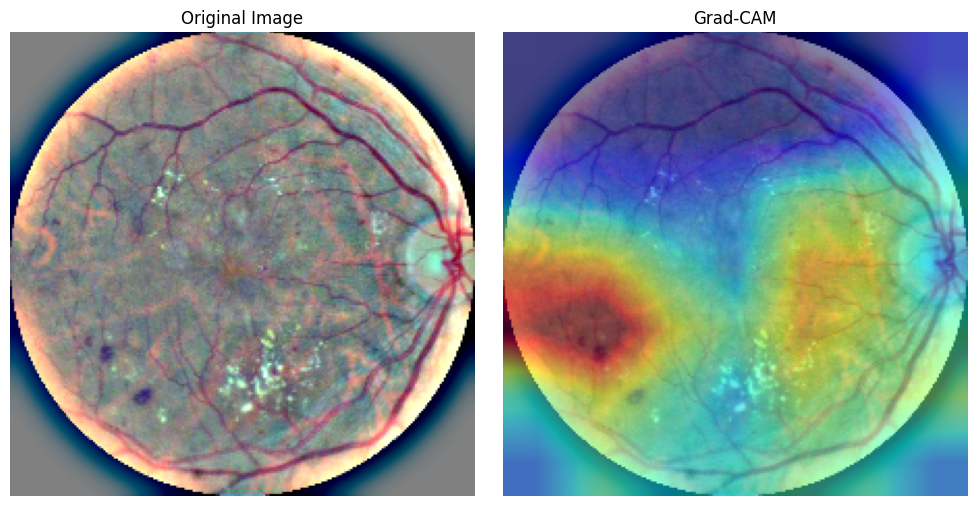

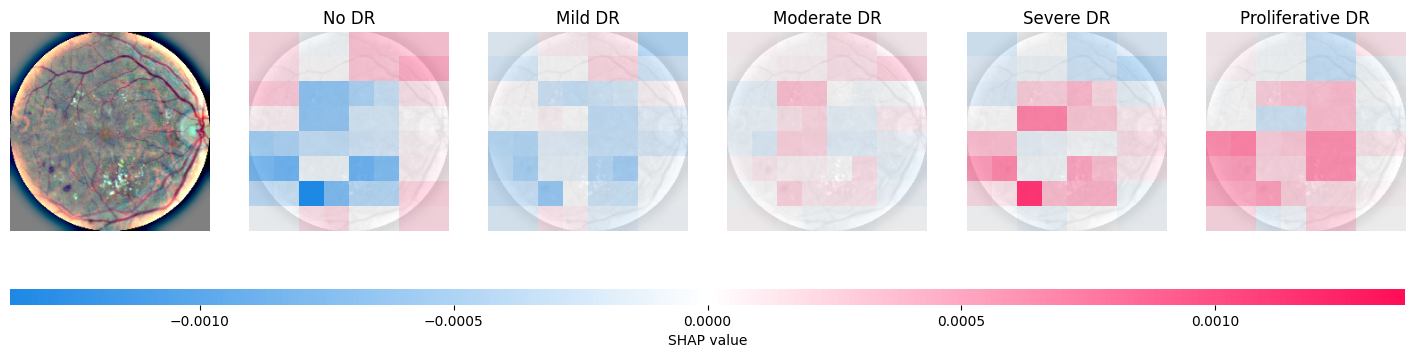

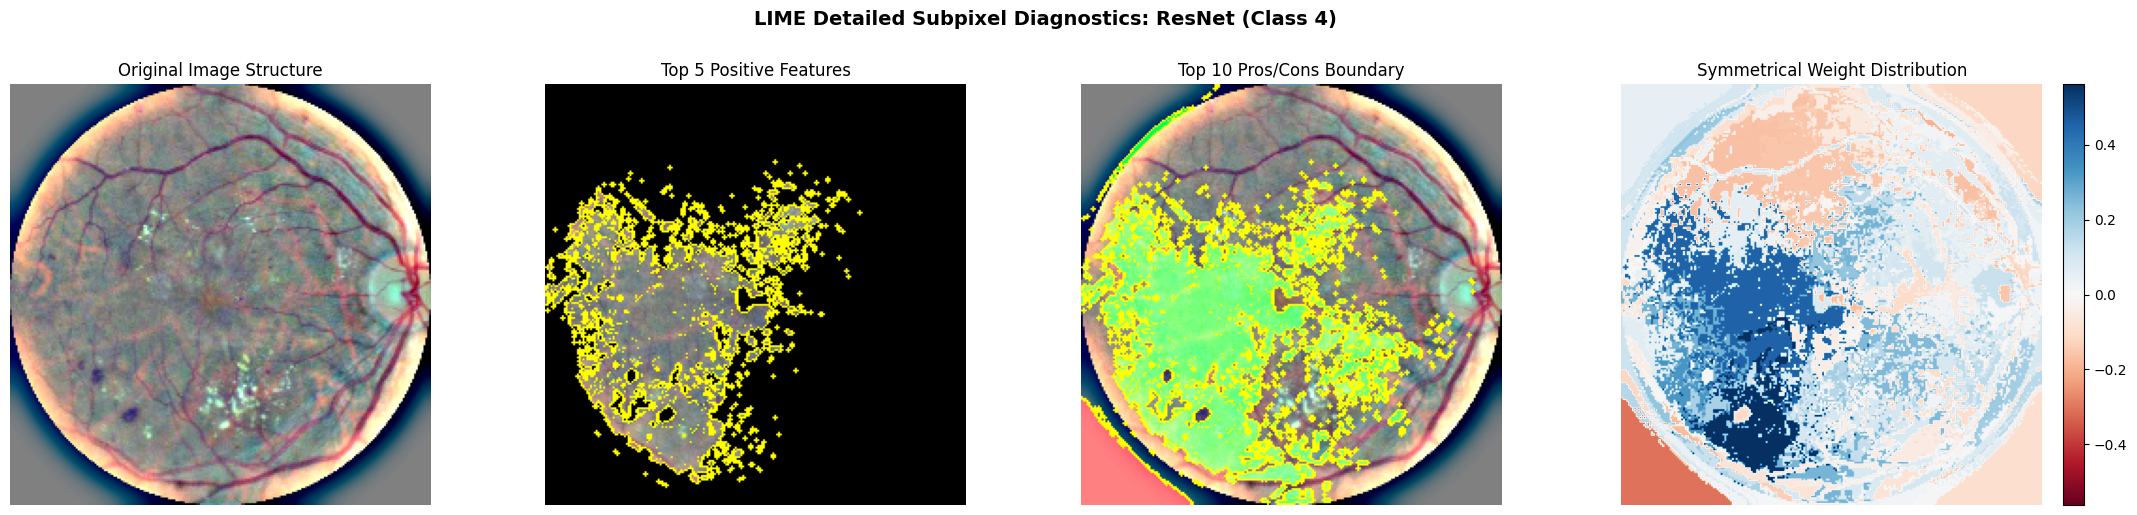

[mem after unloading resnet50 (viz cell)] allocated=0.02 GB  reserved=0.04 GB
[mem after unloading resnet50 (viz cell)] allocated=0.02 GB  reserved=0.04 GB


--- efficientnetb0 ---


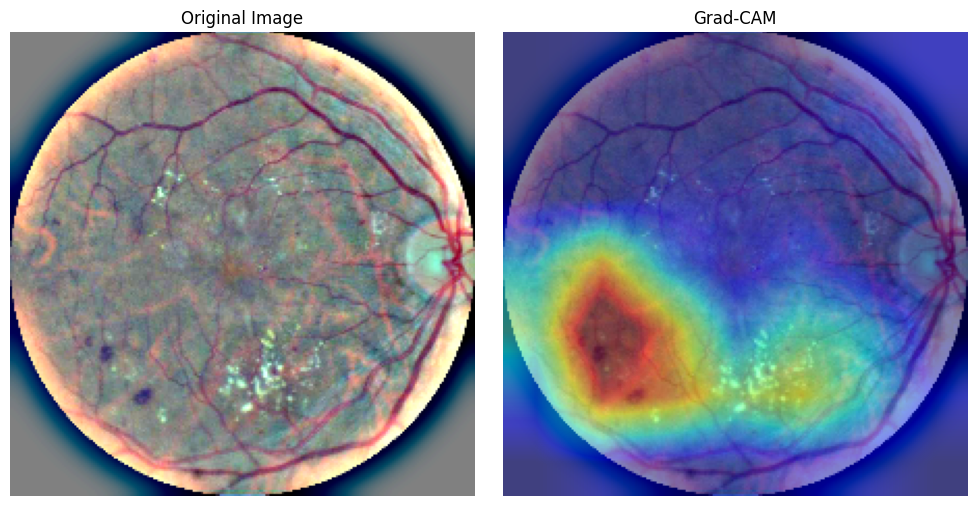

  0%|          | 0/498 [00:00<?, ?it/s]

 25%|██▍       | 124/498 [00:02<00:07, 48.31it/s]

 35%|███▍      | 174/498 [00:02<00:04, 70.92it/s]

 45%|████▍     | 224/498 [00:02<00:02, 98.45it/s]

 55%|█████▌    | 274/498 [00:02<00:01, 130.38it/s]

...

 85%|████████▌ | 424/498 [00:03<00:00, 235.62it/s]

 95%|█████████▌| 474/498 [00:03<00:00, 267.67it/s]

524it [00:03, 296.09it/s]                         

PartitionExplainer explainer: 100%|██████████| 1/1 [00:00<?, ?it/s]

PartitionExplainer explainer: 2it [00:14, 14.15s/it]               

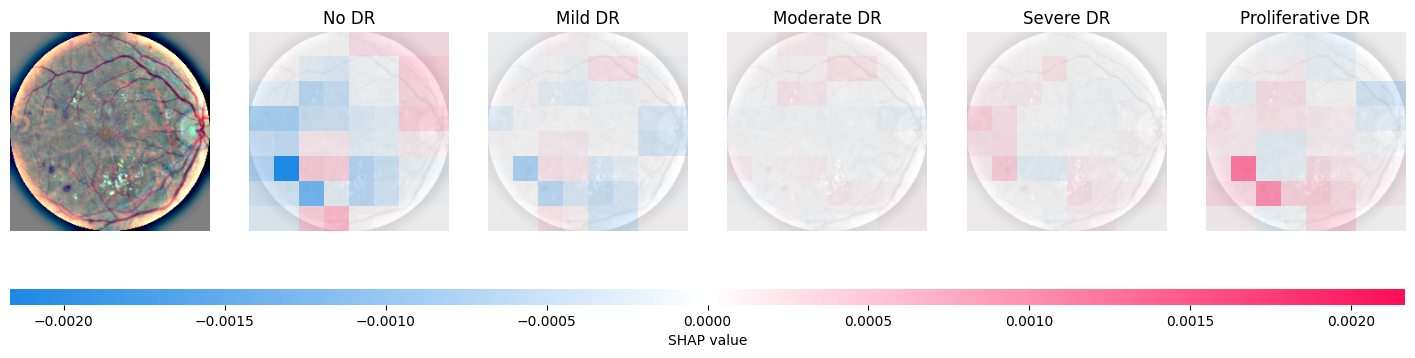

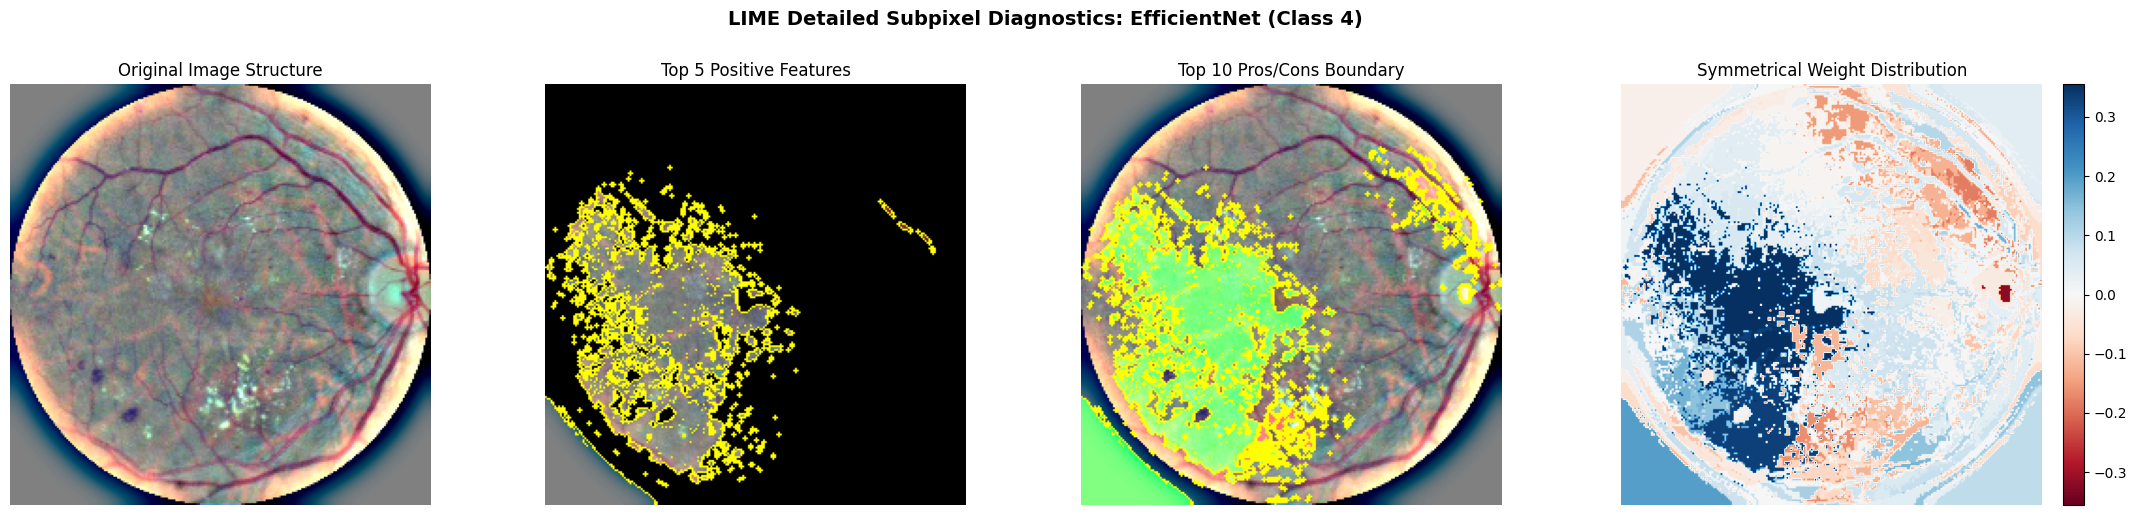

[mem after unloading efficientnetb0 (viz cell)] allocated=0.02 GB  reserved=0.04 GB
[mem after unloading efficientnetb0 (viz cell)] allocated=0.02 GB  reserved=0.04 GB


In [10]:
raw_image, lesion_mask = idrid_subset[0]  # Sample image
drive_model_dir = f"/data/{name}/models"
FIGURES_DIR = f"/data/{name}/results/figures"
os.makedirs(FIGURES_DIR, exist_ok=True)

for model_name in MODEL_NAMES:
    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = mm.load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    image_tensor = test_transform(PILImage.fromarray(raw_image))
    with torch.no_grad():
        predicted_class = model(image_tensor.unsqueeze(0).to(device)).argmax(dim=1).item()

    raw_img_uint8 = engine.unnormalize_to_uint8(image_tensor)
    img_batched = image_tensor.unsqueeze(0).to(device)

    print(f"--- {model_name} ---")

    engine.show_grad_cam(img_batched, raw_img_uint8, predicted_class)
    plt.savefig(os.path.join(FIGURES_DIR, f"gradcam_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    engine.show_shap(raw_img_uint8, target_class=predicted_class, all_classes=True)
    plt.savefig(os.path.join(FIGURES_DIR, f"shap_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    engine.show_lime(raw_img_uint8, target_class=predicted_class)
    plt.savefig(os.path.join(FIGURES_DIR, f"lime_{model_name}.png"), dpi=300, bbox_inches="tight")
    plt.close('all')

    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name} (viz cell)")

    del image_tensor, img_batched, raw_img_uint8

    _engine_cache.clear()
    mm.gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()
    mm.gpu_mem_report(f"after unloading {model_name} (viz cell)")

In [11]:
def _per_image_dir(save_dir, model_name):
    d = os.path.join(save_dir, f"{model_name}_per_image")
    os.makedirs(d, exist_ok=True)
    return d


def run_attributions_on_samples(engine, samples, transform, save_dir, model_name, desc="XAI"):
    per_image_dir = _per_image_dir(save_dir, model_name)

    for i, (raw_img, label) in enumerate(tqdm(samples, desc=desc, ncols=90)):
        img_path = os.path.join(per_image_dir, f"image_{i:04d}.npz")
        if os.path.exists(img_path):
            continue  

        img_tensor = transform(PILImage.fromarray(raw_img))
        try:
            maps = engine.compute_all(img_tensor, label)
            tmp_path = os.path.join(per_image_dir, f"image_{i:04d}.tmp.npz")  # <-- ends in .npz now
            np.savez(
                tmp_path,
                lime=maps['lime'],
                shap=maps['shap'],
                gradcam=maps['gradcam'],
                label=label,
            )
            os.replace(tmp_path, img_path)
        finally:
            img_tensor = None
            mm.clear_memory()
            if i % 5 == 0:
                mm.log_rss(f"{desc}/image {i}")


def assemble_attribution_results(save_dir, model_name, n_images):
    per_image_dir = _per_image_dir(save_dir, model_name)
    lime_maps, shap_maps, gradcam_maps, labels = [], [], [], []
    for i in range(n_images):
        img_path = os.path.join(per_image_dir, f"image_{i:04d}.npz")
        with np.load(img_path) as d:
            lime_maps.append(d['lime'])
            shap_maps.append(d['shap'])
            gradcam_maps.append(d['gradcam'])
            labels.append(d['label'])   
    return {
        'lime': lime_maps,
        'shap': shap_maps,
        'gradcam': gradcam_maps,
        'labels': labels,
    }

 **Computing attribution maps used for localization and faithfulness tests**

In [12]:
N_TEST = 81
SAVE_DIR = f"/data/{name}/xai_maps"
os.makedirs(SAVE_DIR, exist_ok=True)

test_samples = idrid_subset[:N_TEST]

for model_name in MODEL_NAMES:
    save_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")

    if os.path.exists(save_path):
        print(f"\nFound existing maps for {model_name} at {save_path}. Skipping generation.")
        continue

    print(f"\n{'='*60}\n  Computing attribution maps | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = mm.load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    n_already_done = len([
        f for f in os.listdir(_per_image_dir(SAVE_DIR, model_name))
        if f.endswith(".npz")
    ]) if os.path.isdir(_per_image_dir(SAVE_DIR, model_name)) else 0
    print(f"  {n_already_done}/{len(test_samples)} images already checkpointed for {model_name}; resuming...")

    run_attributions_on_samples(
        engine, test_samples, test_transform,
        save_dir=SAVE_DIR, model_name=model_name,
        desc=f"XAI maps ({model_name})",
    )

    attribution_results = assemble_attribution_results(SAVE_DIR, model_name, len(test_samples))

    gts           = np.stack(attribution_results['labels'], axis=0)
    gradcam_maps  = np.stack(attribution_results['gradcam'], axis=0)
    lime_maps     = np.stack(attribution_results['lime'], axis=0)
    shap_maps     = np.stack(attribution_results['shap'], axis=0)

    np.savez(save_path, gts=gts, gradcam=gradcam_maps, lime=lime_maps, shap=shap_maps)
    print(f"Saved {N_TEST} images' attribution maps to {save_path}")

    del attribution_results, gts, gradcam_maps, lime_maps, shap_maps

    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name}")


  Computing attribution maps | Model: resnet50


  0/81 images already checkpointed for resnet50; resuming...


[rss XAI maps (resnet50)/image 0] peak RSS so far = 5467 MB  |  GPU allocated = 296 MB


[rss XAI maps (resnet50)/image 5] peak RSS so far = 5467 MB  |  GPU allocated = 296 MB


[rss XAI maps (resnet50)/image 10] peak RSS so far = 5467 MB  |  GPU allocated = 297 MB


...

[rss XAI maps (efficientnetb0)/image 70] peak RSS so far = 5467 MB  |  GPU allocated = 139 MB


[rss XAI maps (efficientnetb0)/image 75] peak RSS so far = 5467 MB  |  GPU allocated = 139 MB


[rss XAI maps (efficientnetb0)/image 80] peak RSS so far = 5467 MB  |  GPU allocated = 139 MB


Saved 81 images' attribution maps to /data/aveera/xai_maps/attribution_maps_efficientnetb0_test.npz


[mem after unloading efficientnetb0] allocated=0.02 GB  reserved=0.04 GB


# **Localization Evaluation: The pointing game and IoU**


**Pointing Game**: Takes the single highest-attribution pixel in the explanation map and checks if it falls inside the ground-truth lesion region. Scores 1 if yes, 0 if no. It's a strict, all-or-nothing test of whether the model's single most important pixel is disease-relevant.

**IoU**: Measures a model's localization performance by calculating the ratio of the overlap area to the combined total area of the predicted bounding box and the ground-truth bounding box


In [13]:
def binarize_map_adaptive(attribution_map, gt_mask):
    """Schulz et al. (2020) style per-image adaptive thresholding."""
    m = np.asarray(attribution_map, dtype=np.float32)
    n = int(np.asarray(gt_mask).sum())

    if n <= 0:
        return np.zeros_like(m, dtype=np.uint8)
    if n >= m.size:
        return (m > 0).astype(np.uint8)

    top_k_frac = n / m.size
    cutoff = np.percentile(m, 100.0 * (1.0 - top_k_frac))
    return ((m >= cutoff) & (m > 0)).astype(np.uint8)

def binarize_map_batch(maps, gts):
    """Each map is thresholded using its own GT pixel count rather than a global threshold value."""
    assert maps.shape[0] == gts.shape[0]
    return np.stack([binarize_map_adaptive(maps[i], gts[i]) for i in range(maps.shape[0])], axis=0)

localization_rows = []

for model_name in MODEL_NAMES:
    load_path = os.path.join(SAVE_DIR, f"attribution_maps_{model_name}_test.npz")
    data = np.load(load_path)
    gts, gradcam_maps, lime_maps, shap_maps = data['gts'], data['gradcam'], data['lime'], data['shap']

    maps_dict = {"gradcam": gradcam_maps, "lime": lime_maps, "shap": shap_maps}

    print(f"=== {model_name} ===")
    for method, cont_maps in maps_dict.items():
        bin_maps = binarize_map_batch(cont_maps, gts)

        pointing_game = xb.hit(cont_maps, gts)
        iou_score = xb.iou(bin_maps, gts)

        print(f"--- {method} ---")
        print(f"Pointing Game           : {pointing_game:.4f}")
        print(f"IoU                     : {iou_score:.4f}\n")

        localization_rows.append({
            'model': model_name,
            'method': method,
            'pointing_game': round(pointing_game, 4),
            'iou': round(iou_score, 4),
        })

localization_df = pd.DataFrame(localization_rows)
display(localization_df)

=== resnet50 ===


--- gradcam ---
Pointing Game           : 0.5556
IoU                     : 0.0426



--- lime ---
Pointing Game           : 0.7778
IoU                     : 0.0254



--- shap ---
Pointing Game           : 0.6173
IoU                     : 0.0521

=== efficientnetb0 ===


--- gradcam ---
Pointing Game           : 0.7778
IoU                     : 0.0984



--- lime ---
Pointing Game           : 0.8272
IoU                     : 0.0236

--- shap ---
Pointing Game           : 0.7778
IoU                     : 0.0772



,model,method,pointing_game,iou
0,resnet50,gradcam,0.5556,0.0426
1,resnet50,lime,0.7778,0.0254
2,resnet50,shap,0.6173,0.0521
3,efficientnetb0,gradcam,0.7778,0.0984
4,efficientnetb0,lime,0.8272,0.0236
5,efficientnetb0,shap,0.7778,0.0772


In [14]:
RESULTS_DIR = f"/data/{name}/results"
os.makedirs(RESULTS_DIR, exist_ok=True)
localization_df.to_csv(os.path.join(RESULTS_DIR, "localization_summary.csv"), index=False)
print(f"Saved localization summary to {os.path.join(RESULTS_DIR, 'localization_summary.csv')}")

Saved localization summary to /data/aveera/results/localization_summary.csv


In [15]:
_trapz = getattr(np, "trapezoid", None) or np.trapz

In [16]:
def load_attribution_maps(save_dir, model_name, filename_template="attribution_maps_{model}_test.npz"):
    """Loads precomputed attribution maps for one model from disk."""
    with np.load(os.path.join(save_dir, filename_template.format(model=model_name))) as data:
        method_maps = {
            "LIME": np.array(data['lime']),
            "GradCAM": np.array(data['gradcam']),
            "SHAP": np.array(data['shap']),
        }
    return method_maps

# **Faithfulness Evaluation: IROF**

Gradually remove the image regions identified as most important by the XAI method. If the model's confidence drops significantly, it shows those regions were genuinely important, meaning the explanation is more faithful.

**The original IROF paper uses SLIC to segment images into regions**

In [17]:
class FastIROF:
    def __init__(self, model, device, n_segments=100, compactness=10, sigma=1, max_regions=100):
        """Initialize IROF evaluator with model and segmentation parameters"""
        self.model = model.to(device)
        self.device = device
        self.n_segments = n_segments    # SLIC: approximate target number of segments
        self.compactness = compactness  # SLIC: balances color proximity vs. spatial proximity
        self.sigma = sigma              # Gaussian smoothing applied before segmenting
        self.max_regions = max_regions  # Max number of regions to evaluate

        # ImageNet normalization stats used to invert test_transform before segmenting,
        # so SLIC sees real pixel colours/edges instead of normalized (mean-0) values.
        self._imagenet_mean = np.array([0.485, 0.456, 0.406])
        self._imagenet_std = np.array([0.229, 0.224, 0.225])

    def perturb(self, image, mask):
        """Replace selected region in the image with the image's average color (baseline)"""
        baseline = image.mean(dim=[2, 3], keepdim=True)
        image = image.clone()

        if mask.shape != (image.shape[2], image.shape[3]):
            raise ValueError(f"Mask shape {mask.shape} does not match image shape {(image.shape[2], image.shape[3])}")

        mask = mask.unsqueeze(0).unsqueeze(0)  # Add batch and channel dims
        mask = mask.expand_as(image)  # Match shape to image

        # Apply perturbation: replace masked area with baseline
        image = torch.where(mask.bool(), baseline, image)
        return image

    def segment_image(self, x):
        """Segment the original input image (not the attribution map)"""
        img_np = x.squeeze(0).permute(1, 2, 0).cpu().numpy()
        img_np = img_np * self._imagenet_std + self._imagenet_mean  # undo normalization
        img_np = np.clip(img_np, 0.0, 1.0)

        segments = slic(
            img_np.astype(np.float64),
            n_segments=self.n_segments,
            compactness=self.compactness,
            sigma=self.sigma,
            channel_axis=-1,   # img_np is now a real 3-channel RGB image, not a 1-channel map
            start_label=0,
        )
        return segments

    def apply(self, x, a, y, segments, batch_size=8, order="morf", seed=42):
        """order="morf" (Most-Relevant-First) removes regions in DECREASING order of attribution score
        order="random" removes regions in a fixed random order and is only meant to used as a baseline to compare against"""
        if order not in ("morf", "random"):
            raise ValueError(f"order must be 'morf' or 'random', got {order!r}")

        x = x.to(self.device)
        y = y.to(self.device)

        a = a.squeeze()
        if a.ndim == 3:
            a = a.mean(axis=0)

        if a.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Attribution shape {a.shape} does not match image size {(x.shape[2], x.shape[3])}")
        if segments.shape != (x.shape[2], x.shape[3]):
            raise ValueError(f"Segments shape {segments.shape} does not match image size {(x.shape[2], x.shape[3])}")

        # Get original model score for the target class
        with torch.no_grad():
            output = self.model(x)
            orig_score = F.softmax(output, dim=1) * y  # Element-wise multiplication with target mask
            orig_score = orig_score.sum().item()

        # Compute average ATTRIBUTION value within each (fixed, image-derived) region --
        region_scores = [(seg_id, a[segments == seg_id].mean()) for seg_id in np.unique(segments)]

        if order == "morf":
            # Sort by attribution score, HIGHEST first -- remove the regions the
            # explanation thinks are most important first. This is what makes it IROF.
            region_scores.sort(key=lambda pair: pair[1], reverse=True)
        else:  # order == "random"
            rng = np.random.RandomState(seed)
            rng.shuffle(region_scores)

        # Optionally limit number of evaluated regions
        if len(region_scores) > self.max_regions:
            region_scores = region_scores[:self.max_regions]

        scores = [orig_score]
        cumulative_mask = np.zeros_like(segments, dtype=np.uint8)

        with torch.no_grad():
            batch_buffer = []
            for seg_id, _ in region_scores:
                cumulative_mask[segments == seg_id] = 1
                batch_buffer.append(self.perturb(x.clone(), torch.from_numpy(cumulative_mask).to(self.device)))

                if len(batch_buffer) == batch_size:
                    batch = torch.stack(batch_buffer).squeeze(1)
                    output = self.model(batch)
                    for out in output:
                        score = F.softmax(out, dim=0) * y.squeeze()
                        scores.append(score.sum().item())
                    batch_buffer = []
                    del batch, output

            if batch_buffer:  # leftover partial batch
                batch = torch.stack(batch_buffer).squeeze(1)
                output = self.model(batch)
                for out in output:
                    score = F.softmax(out, dim=0) * y.squeeze()
                    scores.append(score.sum().item())
                del batch, output

        eps = 1e-8
        normalized_scores = [s / (orig_score + eps) for s in scores]

        return scores, normalized_scores, segments


def resample_curve(curve, n_points=21):
    x_orig = np.linspace(0, 1, len(curve))
    x_new = np.linspace(0, 1, n_points)
    return np.interp(x_new, x_orig, curve)

In [18]:
def run_irof_on_image(irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx,
                       num_classes=5, transform=test_transform):
    """Runs MoRF IROF for one image, across every attribution method."""

    input_tensor = transform(PILImage.fromarray(raw_img_np)).unsqueeze(0).to("cpu")

    out_max = torch.zeros(1, num_classes)
    out_max[0, predicted_class] = 1

    image_segments = irof_evaluator.segment_image(input_tensor)# Segment the original image once, reuse across all methods

    rows = []
    sorted_curves = {}
    random_curves = {}

    for method_name, maps_array in method_maps.items():
        attr_map = torch.tensor(maps_array[img_idx], dtype=torch.float32)

        _, norm_scores_sorted, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max, segments=image_segments, order="morf")
        _, norm_scores_random, _ = irof_evaluator.apply(x=input_tensor, a=attr_map, y=out_max, segments=image_segments, order="random")

        resampled_sorted = resample_curve(norm_scores_sorted)
        resampled_random = resample_curve(norm_scores_random)

        sorted_curves[method_name] = resampled_sorted
        random_curves[method_name] = resampled_random
        
        irof_auc = float(_trapz(resampled_sorted) / (len(resampled_sorted) - 1))
        rows.append({
            'method':          method_name,
            'image_index':     img_idx,
            'predicted_class': predicted_class,
            'irof_auc':        round(irof_auc, 4),
            'num_regions':     len(np.unique(image_segments))
        })
        del attr_map

    del input_tensor, out_max, image_segments
    mm.clear_memory()
    
    return rows, sorted_curves, random_curves

In [19]:
def run_irof_evaluation(model, samples, predicted_labels, method_maps, device,
                         n_segments=100, compactness=10, sigma=1, max_regions=100,
                         desc="IROF"):
    """Runs the full IROF faithfulness evaluation over samples."""


    irof_evaluator = FastIROF(model=model, device=device, n_segments=n_segments,
                               compactness=compactness, sigma=sigma, max_regions=max_regions)

    all_rows = []
    curves = {m: [] for m in method_maps}
    random_curves = {m: [] for m in method_maps}

    for img_idx in tqdm(range(len(samples)), desc=desc, ncols=90):
        raw_img_np, _ = samples[img_idx]
        predicted_class = int(predicted_labels[img_idx])

        rows, sorted_curves_i, random_curves_i = run_irof_on_image(
            irof_evaluator, raw_img_np, predicted_class, method_maps, img_idx
        )

        all_rows.extend(rows)
        for method_name in method_maps:
            curves[method_name].append(sorted_curves_i[method_name])
            random_curves[method_name].append(random_curves_i[method_name])

    full_df = pd.DataFrame(all_rows)
    return full_df, curves, random_curves

# **Why max_regions=100?**
Limiting to 100 regions ensures a good balance between spatial resolution and runtime efficiency. This number is sufficient to capture meaningful attribution patterns without over-segmenting the image or introducing noise from very small, low-relevance regions. At the same time, it limits the number of model evaluations during IROF scoring, keeping runtime manageable.

This choice follows common practice (e.g., skimage library).

In [20]:
def summarize_and_save_irof(full_df, results_dir, tag="test"):
    """Aggregates per-image IROF results into a per-method summary."""

    summary = (full_df.groupby('method').agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'),
             n_images=('irof_auc', 'count')).reset_index().sort_values('mean_irof_auc')
    )

    summary['mean_irof_auc'] = summary['mean_irof_auc'].round(4)
    summary['std_irof_auc'] = summary['std_irof_auc'].round(4)

    os.makedirs(results_dir, exist_ok=True)
    now = datetime.now().strftime("%Y-%m-%d")
    full_path = os.path.join(results_dir, f'irof_full_{tag}_{now}.csv')
    summary_path = os.path.join(results_dir, f'irof_summary_{tag}_{now}.csv')

    full_df.to_csv(full_path, index=False)
    summary.to_csv(summary_path, index=False)

    print(f"Saved per-image results to {full_path}")
    print(f"Saved summary to {summary_path}")

    return summary

In [21]:
def plot_irof_curves(curves, n_images, title_suffix=""):
    """Plots the mean score-drop curve per method."""

    plt.figure(figsize=(10, 6))
    n_resample_points = len(next(iter(curves.values()))[0])
    fraction_removed = np.linspace(0, 1, n_resample_points)

    for method_name, method_curves in curves.items():
        mean_curve = np.array(method_curves).mean(axis=0)
        plt.plot(fraction_removed, mean_curve, marker="o", markersize=3, label=method_name)

    plt.title(f"IROF Score Drop Comparison{title_suffix} ({n_images} images)")
    plt.xlabel("Fraction of Regions Removed")
    plt.ylabel("Mean Normalized Prediction Score (1.0 = original confidence)")
    plt.grid(True)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=3, frameon=False)
    plt.tight_layout()
    plt.show()
    plt.close() 


def plot_irof_bar(summary, title_suffix=""):
    """Plots a bar chart of mean IROF AUC per method."""
    plt.figure(figsize=(7, 5))
    plt.bar(summary['method'], summary['mean_irof_auc'])
    plt.ylabel("Mean IROF AUC (normalized, lower = more faithful)")
    plt.title(f"Faithfulness Comparison by Attribution Method{title_suffix}")
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    plt.close() 

**Running faithfulness test**


  Faithfulness (IROF) | Model: resnet50


Running faithfulness (IROF) test run on 81 images 



Collected 243 IROF measurements
Saved per-image results to /data/aveera/results/irof_full_resnet50_test_2026-09-16.csv
Saved summary to /data/aveera/results/irof_summary_resnet50_test_2026-09-16.csv

=== Faithfulness (IROF) summary | resnet50 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3466,0.1835,81
0,GradCAM,0.3971,0.1861,81
1,LIME,0.4840,0.2310,81


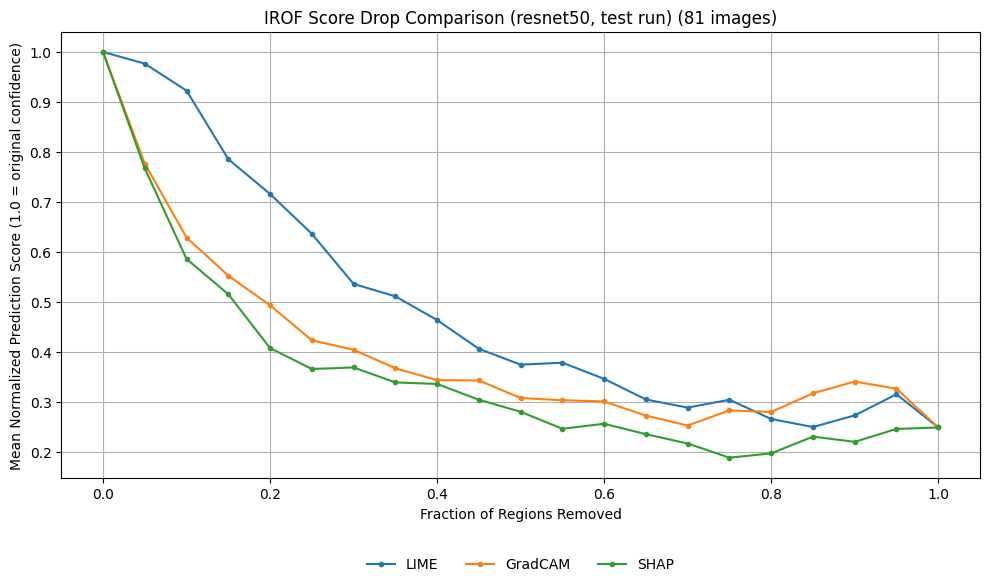

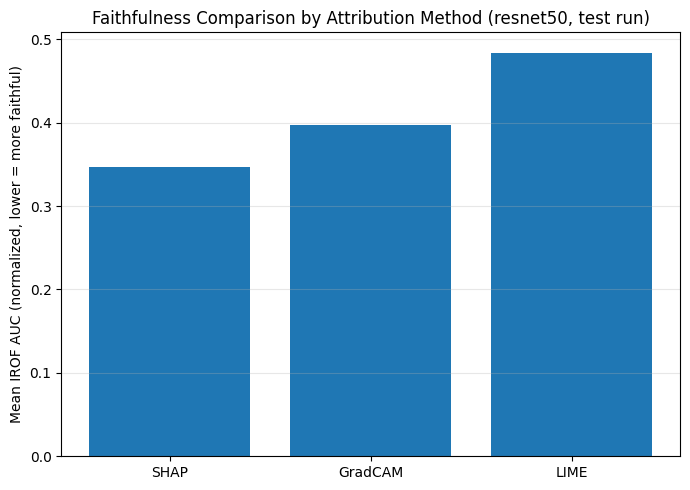

[mem after unloading resnet50] allocated=0.02 GB  reserved=0.04 GB

  Faithfulness (IROF) | Model: efficientnetb0


Running faithfulness (IROF) test run on 81 images 



Collected 243 IROF measurements
Saved per-image results to /data/aveera/results/irof_full_efficientnetb0_test_2026-09-16.csv
Saved summary to /data/aveera/results/irof_summary_efficientnetb0_test_2026-09-16.csv

=== Faithfulness (IROF) summary | efficientnetb0 ===
    (lower mean_irof_auc = confidence drops faster once top-attributed regions
     are removed = more faithful explanation)



,method,mean_irof_auc,std_irof_auc,n_images
2,SHAP,0.3757,0.1595,81
0,GradCAM,0.3825,0.1845,81
1,LIME,0.6052,0.2369,81


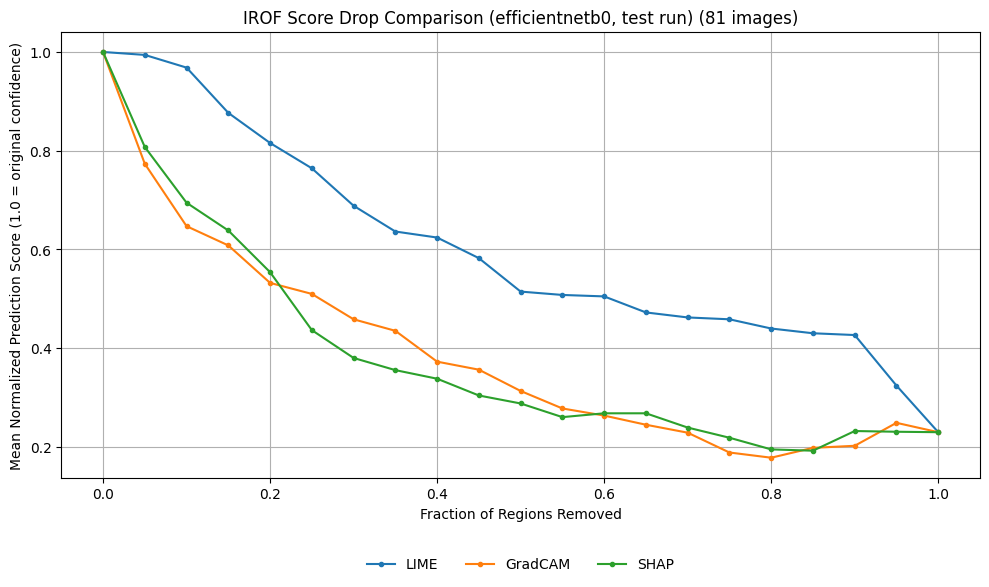

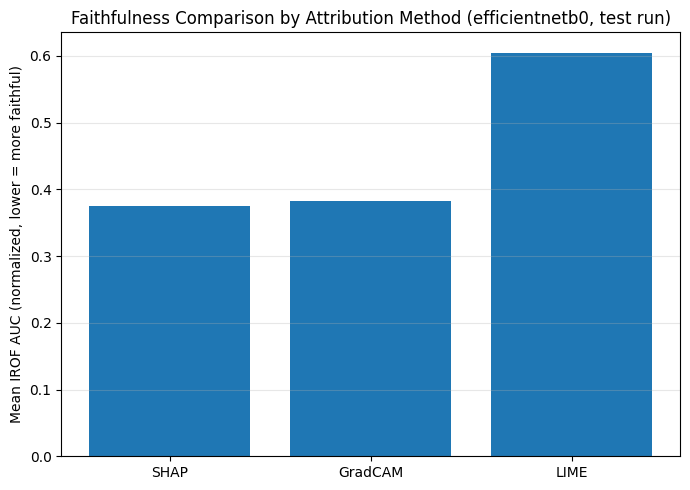

[mem after unloading efficientnetb0] allocated=0.02 GB  reserved=0.04 GB

=== Combined IROF summary (all models) ===


,model,method,mean_irof_auc,std_irof_auc,n_images
2,efficientnetb0,SHAP,0.3757,0.1595,81
0,efficientnetb0,GradCAM,0.3825,0.1845,81
1,efficientnetb0,LIME,0.6052,0.2369,81
5,resnet50,SHAP,0.3466,0.1835,81
3,resnet50,GradCAM,0.3971,0.1861,81
4,resnet50,LIME,0.4840,0.2310,81


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_trapz = getattr(np, "trapezoid", None) or np.trapz

all_irof_dfs = []
irof_curves_by_model = {}

for model_name in MODEL_NAMES:
    print(f"\n{'='*60}\n  Faithfulness (IROF) | Model: {model_name}\n{'='*60}")

    drive_weight_path = os.path.join(drive_model_dir, f"{model_name}_best_model.pth")
    model = mm.load_model(model_name, drive_weight_path, device)

    engine = att_engine.AttributionEngine(model, device)
    _engine_cache[id(model)] = engine

    method_maps = load_attribution_maps(SAVE_DIR, model_name)
    N_FAITHFULNESS_IMAGES = len(next(iter(method_maps.values())))
    faithfulness_samples = idrid_subset[:N_FAITHFULNESS_IMAGES]

    predicted_labels = get_predicted_labels(model, faithfulness_samples, device)

    print(f"Running faithfulness (IROF) test run on {N_FAITHFULNESS_IMAGES} images ")

    full_irof_df, irof_curves, irof_random_curves = run_irof_evaluation(
        model, faithfulness_samples, predicted_labels, method_maps, device=device
    )

    full_irof_df['model'] = model_name
    all_irof_dfs.append(full_irof_df)
    irof_curves_by_model[model_name] = irof_curves

    print(f"\nCollected {len(full_irof_df)} IROF measurements")

    irof_summary = summarize_and_save_irof(
        full_irof_df,
        results_dir=f"/data/{name}/results",
        tag=f"{model_name}_test"
    )

    print(f"\n=== Faithfulness (IROF) summary | {model_name} ===")
    print("    (lower mean_irof_auc = confidence drops faster once top-attributed regions")
    print("     are removed = more faithful explanation)\n")
    display(irof_summary)

    plot_irof_curves(irof_curves, N_FAITHFULNESS_IMAGES, title_suffix=f" ({model_name}, test run)")
    print()
    plot_irof_bar(irof_summary, title_suffix=f" ({model_name}, test run)")

    del method_maps, irof_random_curves
    mm.unload_model(model=model, engine=engine, engine_cache=_engine_cache)
    mm.gpu_mem_report(f"after unloading {model_name}")

full_irof_df_all_models = pd.concat(all_irof_dfs, ignore_index=True)
combined_irof_summary = (
    full_irof_df_all_models.groupby(['model', 'method'])
    .agg(mean_irof_auc=('irof_auc', 'mean'), std_irof_auc=('irof_auc', 'std'), n_images=('irof_auc', 'count'))
    .reset_index()
    .sort_values(['model', 'mean_irof_auc'])
)

combined_irof_summary['mean_irof_auc'] = combined_irof_summary['mean_irof_auc'].round(4)
combined_irof_summary['std_irof_auc'] = combined_irof_summary['std_irof_auc'].round(4)

print("\n=== Combined IROF summary (all models) ===")
display(combined_irof_summary)